# RSNA Pneumonia Detection — 01. EDA 與前處理

這份 notebook 做四件事：
1. 看資料長什麼樣子（EDA）
2. 把 DICOM 轉成 512×512 PNG（之後訓練讀取比較快）
3. 切出 train / val
4. 驗證評分函式是否正確

共用的函式都在 `rsna_utils.py`。

In [1]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import rsna_utils as U

print("raw data:", U.RAW_DIR)
print("png output:", U.PNG_DIR)

raw data: D:\Desktop\vscode\2026DL\data\rsna
png output: D:\Desktop\vscode\2026DL\data\png512


D:\Desktop\vscode\2026DL\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. 標籤概覽
`stage_2_train_labels.csv` 是「一個框一列」，所以同一位病人可能出現好幾列。

In [2]:
labels = U.load_labels()
patients = labels.drop_duplicates("patientId")
print(f"列數: {len(labels)}，病人數: {len(patients)}")
print("\nTarget（0=沒肺炎框, 1=有）：")
print(patients.Target.value_counts())
print("\n細分類別：")
print(patients["class"].value_counts())

列數: 30227，病人數: 26684

Target（0=沒肺炎框, 1=有）：
Target
0    20672
1     6012
Name: count, dtype: int64

細分類別：
class
No Lung Opacity / Not Normal    11821
Normal                           8851
Lung Opacity                     6012
Name: count, dtype: int64


In [3]:
n_boxes = labels.dropna(subset=["x"]).groupby("patientId").size()
print("Target=1 的病人，每人框數分布：")
print(n_boxes.value_counts().sort_index())

Target=1 的病人，每人框數分布：
1    2614
2    3266
3     119
4      13
Name: count, dtype: int64


## 2. 看幾張圖
每一列是一個細分類別。注意第二列「No Lung Opacity / Not Normal」：不正常但**沒有肺炎框**，
模型最容易在這類圖上誤畫框（=那張圖 0 分）。

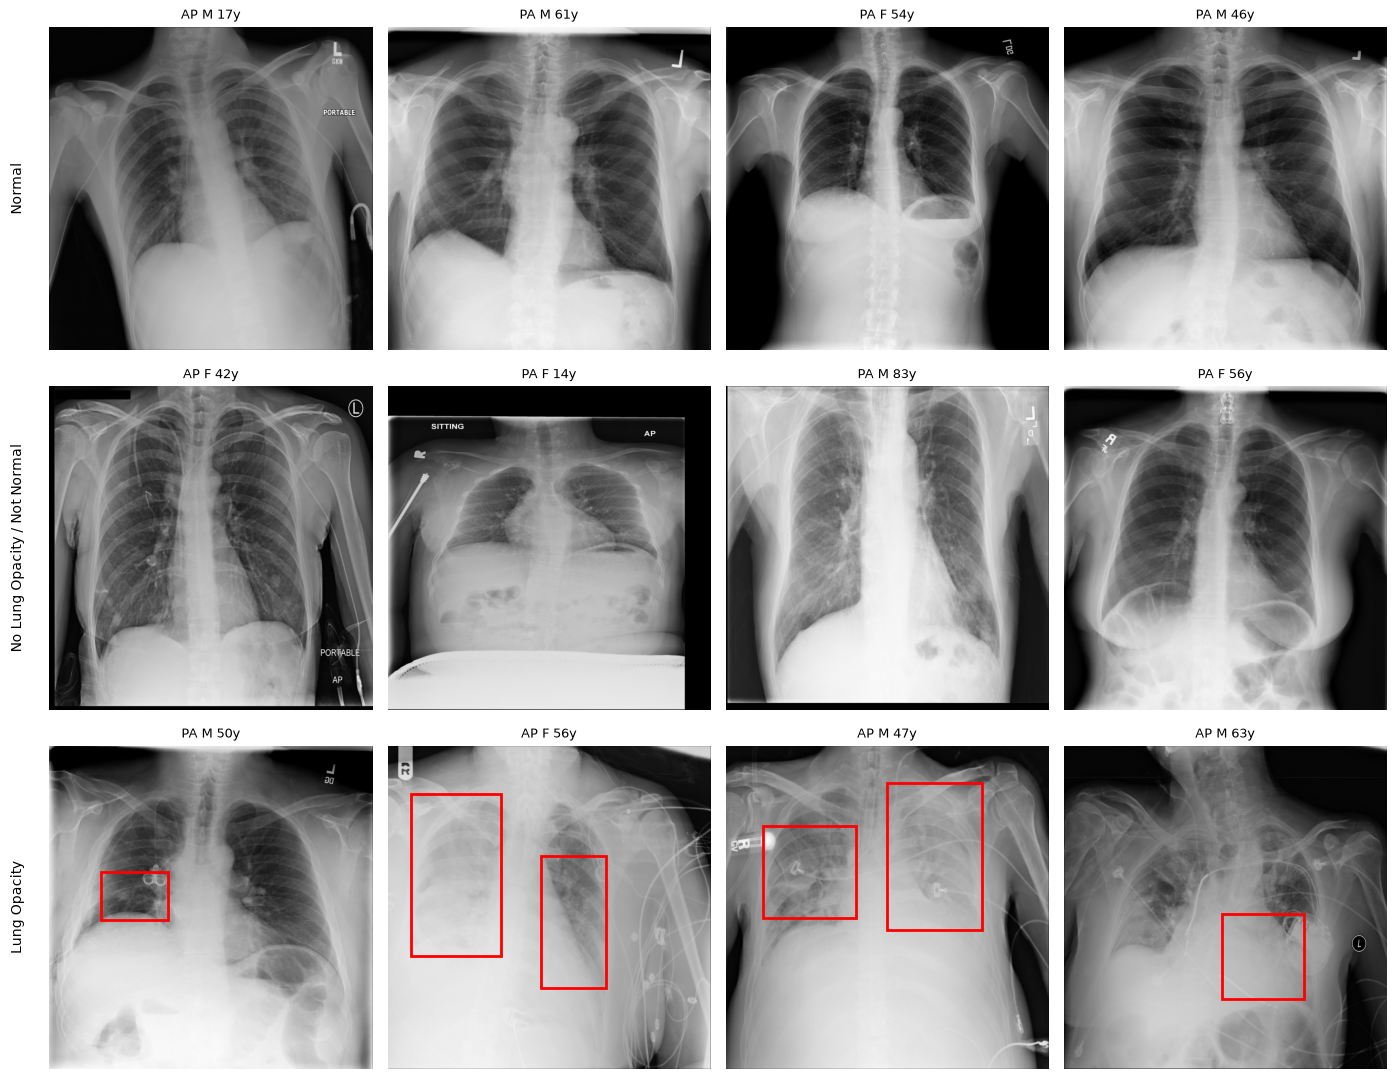

In [4]:
gt_boxes = U.boxes_by_patient(labels)
class_order = ["Normal", "No Lung Opacity / Not Normal", "Lung Opacity"]
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for r, cls in enumerate(class_order):
    pids = patients[patients["class"] == cls].patientId.sample(4, random_state=0)
    for c, pid in enumerate(pids):
        img, meta = U.read_dicom(U.RAW_DIR / "stage_2_train_images" / f"{pid}.dcm")
        ax = axes[r, c]
        ax.imshow(img, cmap="gray")
        for x, y, w, h in gt_boxes[pid]:
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, color="red", lw=2))
        ax.set_title(f"{meta['view']} {meta['sex']} {meta['age']}y", fontsize=9)
        ax.axis("off")
    axes[r, 0].text(-80, 512, cls, rotation=90, va="center", ha="right", fontsize=10)
plt.tight_layout()
plt.show()

## 3. 框的統計
框的大小與位置分布可以幫助判斷 anchor 尺寸、資料擴增方式是否合理。

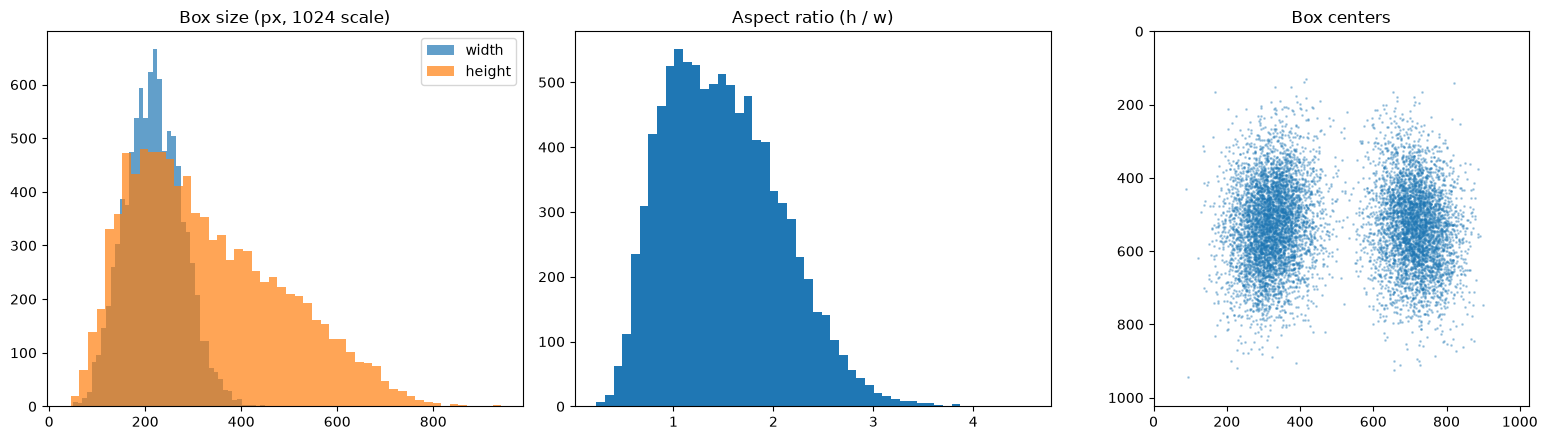

        width  height
count  9555.0  9555.0
mean    218.5   329.3
std      59.3   157.8
min      40.0    45.0
25%     177.0   203.0
50%     217.0   298.0
75%     259.0   438.0
max     528.0   942.0


In [5]:
b = labels.dropna(subset=["x"]).copy()
b["cx"] = b.x + b.width / 2
b["cy"] = b.y + b.height / 2

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(b.width, bins=50, alpha=0.7, label="width")
axes[0].hist(b.height, bins=50, alpha=0.7, label="height")
axes[0].set_title("Box size (px, 1024 scale)")
axes[0].legend()
axes[1].hist(b.height / b.width, bins=50)
axes[1].set_title("Aspect ratio (h / w)")
axes[2].scatter(b.cx, b.cy, s=1, alpha=0.3)
axes[2].set_xlim(0, 1024)
axes[2].set_ylim(1024, 0)
axes[2].set_aspect("equal")
axes[2].set_title("Box centers")
plt.tight_layout()
plt.show()
print(b[["width", "height"]].describe().round(1))

## 4. DICOM → 512×512 PNG
第一次跑大約需要數分鐘（看 CPU）。已經轉過的檔案會自動跳過，中斷後可以直接重跑。
同時會把 DICOM 檔頭的年齡 / 性別 / 拍攝方向存成 `*_meta.csv`。

In [6]:
train_meta = U.convert_split("train")
test_meta = U.convert_split("test")
print(len(train_meta), len(test_meta))

train:   0%|          | 0/26684 [00:00<?, ?it/s]

train:   0%|          | 1/26684 [00:10<74:23:10, 10.04s/it]

train:   1%|          | 257/26684 [00:10<12:13, 36.02it/s] 

train:   2%|▏         | 513/26684 [00:11<06:44, 64.72it/s]

train:   4%|▎         | 961/26684 [00:11<02:44, 155.98it/s]

train:   5%|▍         | 1201/26684 [00:13<02:54, 146.28it/s]

... (222 outputs left out)

test:  89%|████████▉ | 2664/3000 [00:19<00:01, 229.87it/s]

test:  92%|█████████▏| 2753/3000 [00:19<00:00, 259.32it/s]

test: 100%|██████████| 3000/3000 [00:19<00:00, 152.54it/s]

26684 3000


### 檔頭資訊與 Target 的關係
拍攝方向（AP = 前後，通常是躺著或病比較重的人在拍；PA = 後前，站著拍）可能跟肺炎比例有關。

各拍攝方向的肺炎比例：
       mean  count
view              
AP    0.383  12173
PA    0.093  14511

各性別的肺炎比例：
      mean  count
sex              
F    0.217  11518
M    0.231  15166


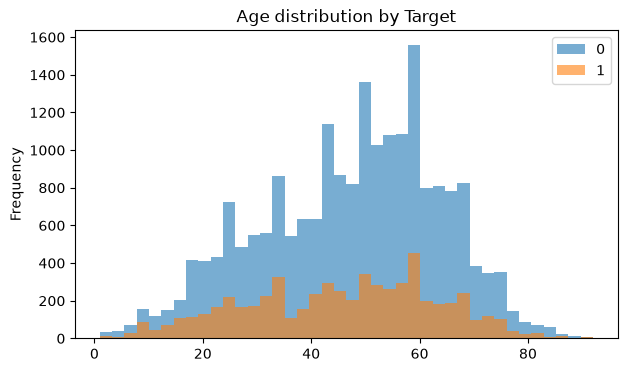

In [7]:
m = train_meta.merge(patients[["patientId", "Target", "class"]], on="patientId")
print("各拍攝方向的肺炎比例：")
print(m.groupby("view").Target.agg(["mean", "count"]).round(3))
print("\n各性別的肺炎比例：")
print(m.groupby("sex").Target.agg(["mean", "count"]).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
m[m.age <= 100].groupby("Target").age.plot.hist(bins=40, alpha=0.6, ax=ax, legend=True)
ax.set_title("Age distribution by Target")
plt.show()

## 5. 切 train / val
依細分類別分層抽樣 15% 當 validation，存成 `data/png512/split.csv`，**全組都用同一份切法**，實驗結果才能互相比較。

In [8]:
split = U.make_split(labels, val_ratio=0.15, seed=42)
split.to_csv(U.PNG_DIR / "split.csv", index=False)
print(split.groupby(["split", "class"]).size().unstack())

class  Lung Opacity  No Lung Opacity / Not Normal  Normal
split                                                    
train          5110                         10048    7523
val             902                          1773    1328


## 6. 驗證評分函式
用幾個可以手算的情況確認 `score_image` 沒寫錯。

In [9]:
gt = np.array([[100, 100, 200, 200]])
cases = {
    "完全命中": (gt, gt),
    "沒預測（有病）": (gt, np.zeros((0, 4))),
    "沒病卻畫框": (np.zeros((0, 4)), gt),
    "沒病也沒畫框": (np.zeros((0, 4)), np.zeros((0, 4))),
    "命中 + 多一個錯框": (gt, np.array([[100, 100, 200, 200], [600, 600, 100, 100]])),
    "偏移 20px (IoU≈0.68)": (gt, np.array([[120, 120, 200, 200]])),
}
for name, (g, p) in cases.items():
    print(f"{name:<22} -> {U.score_image(g, p)}")

完全命中                   -> 1.0
沒預測（有病）                -> 0.0
沒病卻畫框                  -> 0.0
沒病也沒畫框                 -> None
命中 + 多一個錯框             -> 0.5
偏移 20px (IoU≈0.68)     -> 0.75


預期結果：完全命中 1.0；沒預測 0.0；沒病卻畫框 0.0；沒病沒畫框 None（不算進平均）；
多一個錯框 0.5（每個閾值都是 1/(1+1+0)）；偏移 20px 只有 IoU 閾值 < 0.68 的 6 個閾值算命中 → 6/8 = 0.75。

In [10]:
val_ids = split[split.split == "val"].patientId
val_gt = {pid: gt_boxes[pid] for pid in val_ids}

oracle = {pid: (g, np.ones(len(g))) for pid, g in val_gt.items()}
print("拿真實框當預測（上限）:", U.mean_score(val_gt, oracle))
print("全部不預測:", U.mean_score(val_gt, {}))

拿真實框當預測（上限）: 1.0
全部不預測: 0.0


「全部不預測」得 0 分：沒病的圖不計分，有病的圖全都 0 分。
所以模型的目標是**有病的圖框得準**，同時**沒病的圖一個框都不要畫**。

## 7. 檢查 Dataset
確認 PNG、框座標縮放、水平翻轉都正確。紅框應該落在肺部的白霧區域上。

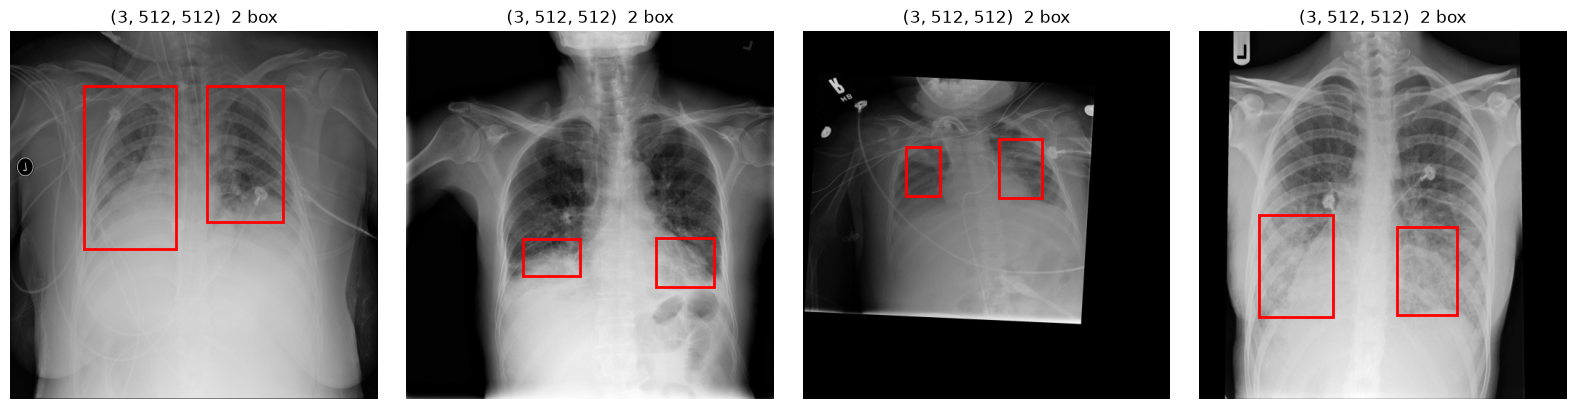

In [11]:
train_ids = split[split.split == "train"].patientId
ds = U.RSNADetectionDataset(train_ids, gt_boxes, U.PNG_DIR / "train", hflip_prob=0.5)
pos_idx = [i for i, pid in enumerate(ds.ids) if len(gt_boxes[pid]) > 0][:4]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, i in zip(axes, pos_idx):
    img, tgt = ds[i]
    ax.imshow(img[0], cmap="gray")
    for x1, y1, x2, y2 in tgt["boxes"]:
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="red", lw=2))
    ax.set_title(f"{tuple(img.shape)}  {len(tgt['boxes'])} box")
    ax.axis("off")
plt.tight_layout()
plt.show()